In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from astropy import units as u
import toast.qarray as qa
import toast

Let's start by making a basic 'pointing' array. This will be like a constant elevation scan.

In [142]:
N = int(1e4)
t = np.arange(N)
lon_arr = np.ones(N)
lat_arr = np.sin(0.2*np.arange(N)) + 2
psi_arr = np.zeros(N)

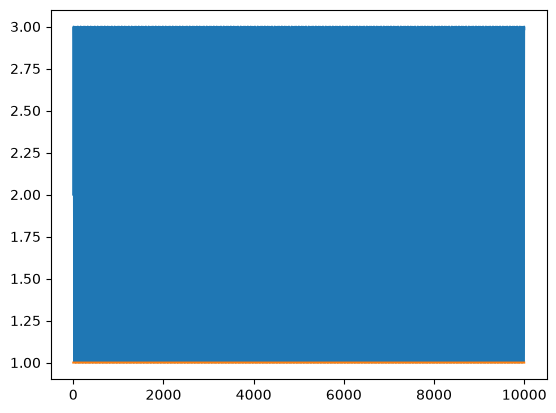

In [143]:
plt.plot(t, lat_arr)
plt.plot(t, lon_arr)
plt.show()

This is what the jitter operator currently does

In [145]:
# 1. Initialize the random generator (optional seed for reproducibility)
rng = np.random.default_rng(seed=42)

# 2. Generate samples
# parameters: loc = mean, scale = standard deviation, size = shape of output
draws = [rng.normal(loc=0.0, scale=1.0, size=N),
        rng.normal(loc=0.0, scale=1.0, size=N),
        rng.normal(loc=0.0, scale=1.0, size=N)]

sigma_az = (30*u.arcmin.to(u.rad))
sigma_el = (30*u.arcmin.to(u.rad))
sigma_psi = (30*u.arcmin.to(u.rad))

# Make a sinusoidal term
# sine_term = sin_amp * np.sin(sin_freq * t)

# Make the jitter terms
lon_noise = -sigma_az * draws[0] #- sine_term
lat_noise = sigma_el * draws[1] #+ sine_term
psi_noise = sigma_psi * draws[2] # No sine term for corotator

lon_arr += lon_noise
lat_arr += lat_noise
psi_arr += psi_noise

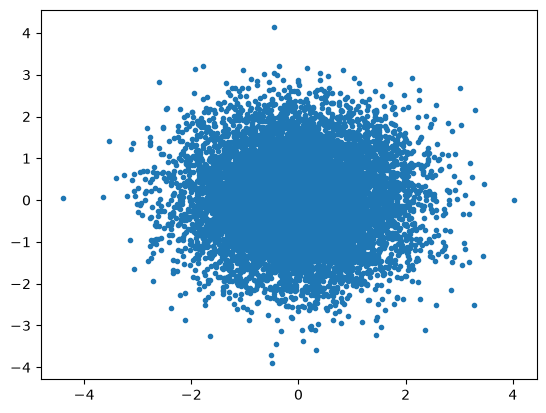

In [146]:
plt.plot(draws[0], draws[1], '.')
plt.show()

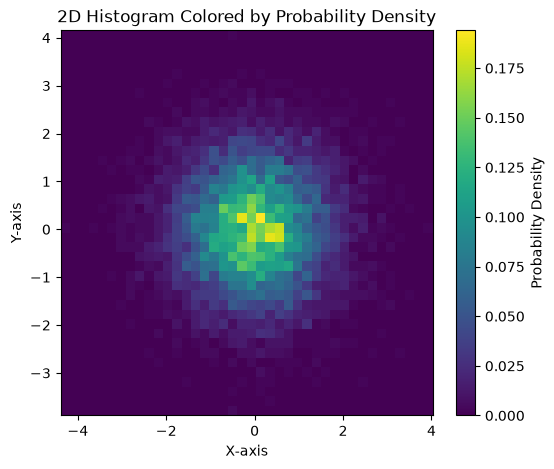

In [147]:
fig, ax = plt.subplots(figsize=(6, 5))

# Plot 2D histogram with density normalization
counts, xedges, yedges, im = ax.hist2d(draws[0], draws[1], bins=40, density=True, cmap="viridis")

ax.set_xlabel("X-axis")
ax.set_ylabel("Y-axis")
ax.set_title("2D Histogram Colored by Probability Density")

# Add a colorbar
fig.colorbar(im, ax=ax, label="Probability Density")
plt.show()


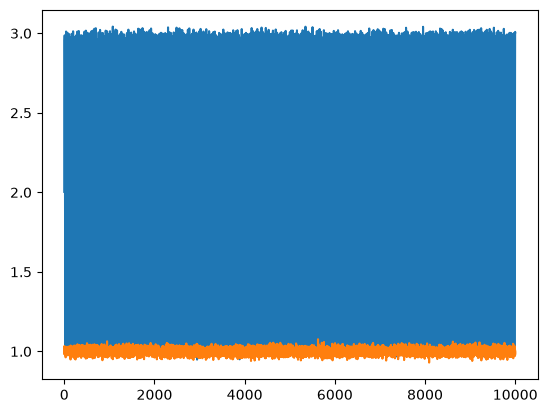

In [148]:
plt.plot(t, lat_arr)
plt.plot(t, lon_arr)

Option 2

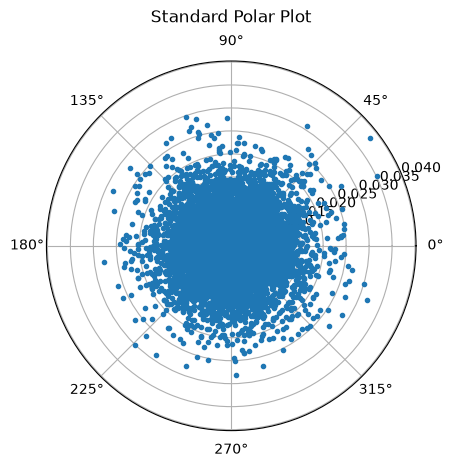

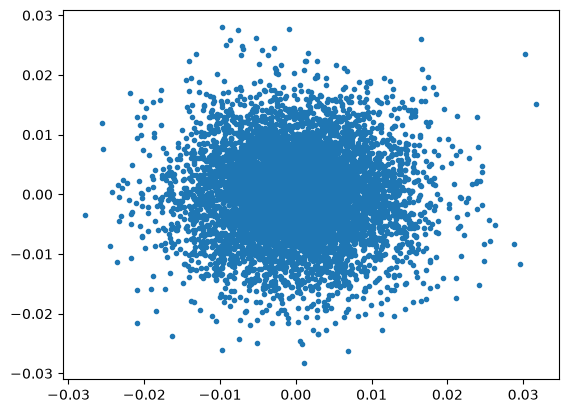

In [161]:
r = sigma_az * draws[0]

theta = np.random.random(N)*2*np.pi

adjusted_theta = np.where(r < 0, theta + np.pi, theta)
adjusted_r = np.abs(r)

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})

# Plot the data (theta always comes first)
# for i in range(N):
#     # print(np.rad2deg(theta[i]), r[i])
#     ax.plot(adjusted_theta[i], adjusted_r[i], '.', linewidth=2, label='Cardioid')
ax.plot(adjusted_theta, adjusted_r, '.', linewidth=2, label='Cardioid')

az_el_arr = np.zeros((N, 2))

az_el_arr[:, 0] = np.cos(adjusted_theta)*adjusted_r
az_el_arr[:, 1] = np.sin(adjusted_theta)*adjusted_r

# Customizations
ax.set_title("Standard Polar Plot", va='bottom')
ax.grid(True)

plt.show()

plt.plot(az_el_arr[:, 0],az_el_arr[:, 1], '.')

Compare the methods

/tmp/ipykernel_52088/3348415269.py:12: UserWarning: Adding colorbar to a different Figure <Figure size 600x500 with 2 Axes> than <Figure size 600x500 with 2 Axes> which fig.colorbar is called on.
  fig.colorbar(im, ax=ax, label="Probability Density")


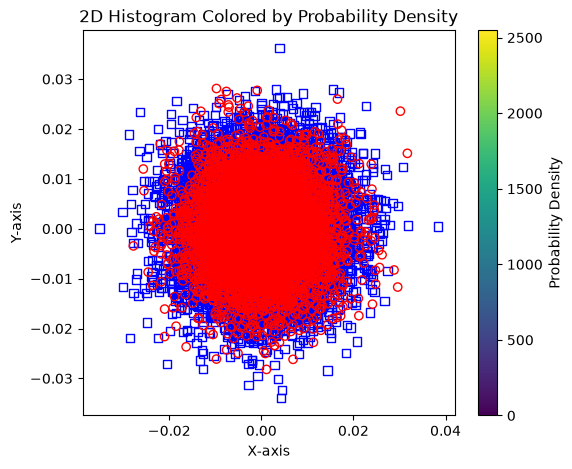

In [169]:
fig, ax = plt.subplots(figsize=(6, 5))

# Plot 2D histogram with density normalization
plt.scatter(lon_noise, lat_noise, marker='s', facecolor='none', edgecolor='b')
plt.scatter(az_el_arr[:, 0],az_el_arr[:, 1], marker='o', facecolor='none', edgecolor='r')

ax.set_xlabel("X-axis")
ax.set_ylabel("Y-axis")
ax.set_title("2D Histogram Colored by Probability Density")

# Add a colorbar
fig.colorbar(im, ax=ax, label="Probability Density")
plt.show()


Using scipy stats

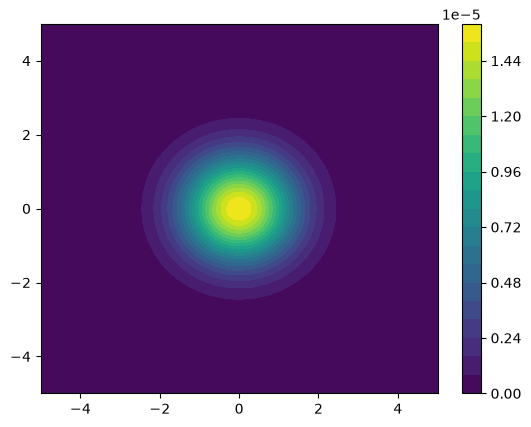

In [ ]:
import scipy.stats as stats
mean = 0
std_dev = 1

x = np.arange(-5.0, 5.01, 0.01)
y = np.arange(-5.0, 5.01, 0.01)
X, Y = np.meshgrid(x, y)

def gaussian_cdf(X, Y, mean, std):
    term1 = (-stats.norm.cdf(X, mean, std) + stats.norm.cdf(X+0.01, mean, std))
    term2 = (-stats.norm.cdf(Y, mean, std) + stats.norm.cdf(Y+0.01, mean, std))
    return term1*term2

def uniform_cdf(X, Y, mean, scale):
    term1 = (-stats.uniform.cdf(X, loc=mean-scale/2, scale=scale) + stats.uniform.cdf(X+0.01, loc=mean-scale/2, scale=scale))
    term2 = (-stats.uniform.cdf(Y, loc=mean-scale/2, scale=scale) + stats.uniform.cdf(Y+0.01, loc=mean-scale/2, scale=scale))
    return term1*term2


def option2(X, Y, mean, scale):
    r_distrib = stats.norm.pdf()
    term1 = (-stats.uniform.cdf(X, loc=mean-scale/2, scale=scale) + stats.uniform.cdf(X+0.01, loc=mean-scale/2, scale=scale))
    term2 = (-stats.uniform.cdf(Y, loc=mean-scale/2, scale=scale) + stats.uniform.cdf(Y+0.01, loc=mean-scale/2, scale=scale))
    return term1*term2


gaussZ = gaussian_cdf(X, Y, mean, std_dev)
plt.contourf(X, Y, gaussZ, levels=20, cmap='viridis')
plt.colorbar()  # Adds a color legend
plt.show()

In [27]:
sigma = (120*u.arcsec).to(u.deg)

n_sample=100000
rng = np.random.default_rng()

random_draw = rng.normal(loc=0.0, scale=1.0, size=n_sample)
noise_term = random_draw * sigma

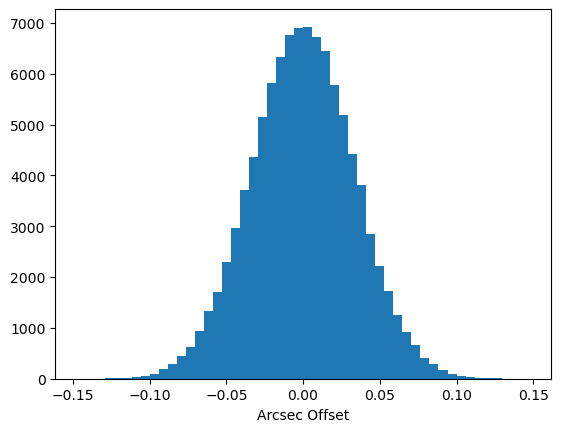

In [28]:
plt.hist(noise_term, bins=50)
plt.xlabel("Arcsec Offset")
plt.show()

In [30]:
print(2*u.arcmin.to(u.deg))

0.03333333333333333
